# Updated DQN benchmark: metrics 1, 6, 7, 8, 12

변경된 `Benchmark-DQN.ipynb`의 최신 결과를 읽어 **세 density를 합친 후** scGen / CPA / CellOracle와 비교합니다. 저장된 reward version이 현재 알고리즘과 일치하는지 검사합니다. 이전 도구의 train/valid/query/test split은 재생성하거나 변경하지 않습니다.

### 이번 비교의 다섯 패널
1. Cell-wise cosine boxplot: 모든 예측 × 실제 KO 세포쌍.
2. Gene-wise residual boxplot: 유전자별 평균 발현 잔차.
3. Pearson correlation: 2,000개 유전자 평균 발현 벡터의 상관.
4. Expression prediction error: 유전자 평균 잔차의 MAE / RMSE.
5. Cosine distribution: 1번과 같은 값의 분포(공통 50개 bin). 별도의 독립 점수는 아닙니다.
그림 번호 1–5는 원본 지표 1·6·7·8·12에 대응합니다. 전체 제목과 오른쪽 아래 설명은 생략합니다. 1·2번 boxplot 아래 중앙값, 3번 Pearson 값, 4번 MAE/RMSE bar 위 값은 빨간색으로 표시합니다.

최신 비교 그림/CSV는 알고리즘 버전별 새 디렉터리에 저장하여 이전 벤치마크/CSV를 보존합니다. 그림 3·4번은 원본처럼 barplot이고 5번은 histogram이며, 억지로 boxplot으로 변환하지 않습니다.

**실행 도구: scGen, CPA, CellOracle + 기존 DQN 참고군.** scGen/CPA는 ATF6 KO 학습을 허용하고, CellOracle는 training control과 공개 human promoter GRN만 사용합니다. GEARS는 여러 perturbation용 도구로 두 조건 실험에서는 실행하지 않았고, scTenifoldKnk 조절 점수를 발현 행렬로 바꾸지 않습니다.

## 공통 평가 계약
- Control `3x_neg_ctrl_pMJ144-1` → ATF6 perturbation `ATF6_only_pMJ145`의 발현 예측.
- 기존 Validation 2의 **2,000개 평가 유전자 및 순서**를 고정합니다. 현재 DQN 전체 목록은 3,000개이며 평가 패널과 다릅니다. HVG/DEG를 다시 선정하지 않습니다.
- 전체 유전자 raw counts → CP10K → log1p 후 패널 추출. 패널에서 다시 정규화하지 않습니다.
- Control 1,715개와 저장된 Validation 2 KO 1,202개를 조건별 **70/10/20% train/valid/test**로 나눕니다. 원본의 나머지 KO 세포는 이 실험에서 제외합니다.
- 학습 Control 1,200 / KO 840; 검증 172 / 121; 최종 평가 Control 343 / KO 241. 모든 외부 도구는 동일한 held-out Control 343개로 예측하고 동일한 KO 241개로 평가합니다.
- Boxplot 1: 모든 예측 세포 × 실제 KO 세포 쌍 cosine. Boxplot 2: 유전자별 `mean(predicted) - mean(measured KO)` 2,000개. 마름모는 평균입니다.
- DQN의 세 density band는 기존 821/326/55개 표본을 합쳐 참고 결과로 표시합니다. DQN 1,202개 예측을 동일 KO test 241개에 평가하지만 **DQN은 test 세포를 학습한 결과이므로 공정한 holdout 순위에서 제외**합니다.

**해석 제한:** 처음 보는 ATF6 KO 예측이 아니라 학습한 ATF6 perturbation의 held-out cell 비교입니다. 패널 자체는 전체 KO/control 라벨로 선정되어 독립적인 feature selection은 아닙니다. 세포쌍은 독립 표본이 아니며 p-value 검정에 사용하지 않습니다. 생물학적 replicate holdout도 아닙니다. CRISPR knockdown과 완전한 gene deletion은 다릅니다.

## 구현과 전처리 차이
- 공식 scGen 2.1.1 pinned commit, CPA 0.8.8: hidden 256 / latent 32, 100 epochs, CPU 4 threads, seed 42. scGen의 scvi splitter에 공통 인덱스를 적용하고 latent shift는 train 세포만 사용합니다. CPA는 공통 validation에서 best checkpoint를 선택합니다. hyperparameter search를 실시한 최종 최적 성능은 아닙니다.
- CellOracle 0.20.0: public hg38 promoter GRN, training-control PCA/GRN, k=30 smoothing, alpha=1, propagation=3. Query smoothing에도 training control 이웃만 사용합니다. 고정 패널에서 control-expressed CV QC 유전자가 334개라 upstream QC rank를 333으로 제한합니다. **평가 패널 2,000개는 필터링하지 않습니다.** GRN prior coverage와 실제 ATF6 변경 유전자 수는 manifest에 저장합니다.
- Gaussian decoder의 음수 log-expression은 0으로 제한하고 clipping 개수를 기록합니다. CellOracle의 smoothing과 decoder clipping은 결과에 영향을 줍니다. 높은 발현 cosine만으로 KO 효과 예측 정확도를 주장하지 말고 baseline, MAE/RMSE도 확인합니다.
- 모델/예측/manifest/split/그림을 저장합니다. 저장된 예측은 split·유전자·query 매핑을 다시 검증하여 읽습니다. 도구를 실행한 척하는 대체 모델은 사용하지 않습니다.


In [1]:
from pathlib import Path
import os
import subprocess
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd()
if not (ROOT / 'total_benchmark.py').is_file():
    ROOT = ROOT / 'RL'
if not (ROOT / 'total_benchmark.py').is_file():
    raise FileNotFoundError('Run from RL or its repository parent')
sys.path.insert(0, str(ROOT))
from total_benchmark import (
    DATA_URL, CONDITIONS, prepare_data, reuse_supervised_split,
    candidate_catalog, run_five_metric_benchmark, evaluate_expression, validate_dqn_export,
)
DATA_PATH = Path('AdamsonWeissman2016_GSM2406677_10X005.h5ad')
REFERENCE_DIR = ROOT / 'scDQN_results/atf6_perturbation/deg1994_required6_fixed_umap_v1/control_condition_atf6_entropy_branch_dqn/gaussian_ko_comparison'
RUN_DIR = ROOT / 'total_benchmark_results/supervised_atf6_v1'
INPUT_DIR = RUN_DIR / 'inputs'
DQN_PROVENANCE = validate_dqn_export(REFERENCE_DIR, ROOT / 'Benchmark-DQN.ipynb')
OUTPUT_DIR = RUN_DIR / ('evaluation_' + DQN_PROVENANCE['reward_version'] + '_metrics_1_6_7_8_12')
ENV_ROOT = Path.home() / '.conda/envs'
TOOL_PYTHONS = {
    'scGen': ENV_ROOT / 'atf6-benchmark-py310/bin/python',
    'CPA': ENV_ROOT / 'atf6-benchmark-py310/bin/python',
    'CellOracle': ENV_ROOT / 'celloracle/bin/python',
}
SEED, EPOCHS = 42, 100
FORCE_RETRAIN = False
print('Notebook kernel:', sys.executable)
print('Run directory:', RUN_DIR)


Notebook kernel: /home/Data_Drive_8TB/kykim/.conda/envs/scrna/bin/python
Run directory: /home/Data_Drive_8TB/kykim/0. Jupyter/RL/total_benchmark_results/supervised_atf6_v1


In [2]:
archived_data = prepare_data(ROOT / DATA_PATH, REFERENCE_DIR)
benchmark_data = reuse_supervised_split(archived_data, INPUT_DIR)
if benchmark_data.split['seed'] != SEED:
    raise ValueError('Requested seed differs from the original trained split')
print('Latest DQN algorithm:', DQN_PROVENANCE['reward_version'])
print('Latest export SHA256:', DQN_PROVENANCE['export_sha256'])
display(pd.DataFrame(benchmark_data.split['counts']))
display(candidate_catalog(training_allowed=True))
print('Frozen genes:', len(benchmark_data.genes), 'SHA256:', benchmark_data.gene_hash)
print('Query control:', benchmark_data.control.n_obs, 'Test KO:', len(benchmark_data.measured))
print('DQN reference density bands:', np.bincount(benchmark_data.density_band))


Latest DQN algorithm: atf6_decrease_only_consistent_reference_v4
Latest export SHA256: cd5c3747af64d48ec81bfd99dcfeff3eab4044020be04d08d5a54506977864bc


,test,train,valid
3x_neg_ctrl_pMJ144-1,343,1200,172
ATF6_only_pMJ145,241,840,121


,method,status,reason,source
0,GEARS,not_run_two_condition_scope,GEARS is designed/tested for multiple perturba...,https://github.com/snap-stanford/GEARS
1,CPA,ready_for_supervised_training,ATF6 KO training permitted; shared held-out ce...,https://github.com/theislab/cpa
2,scGen,ready_for_supervised_training,ATF6 KO training permitted; shared held-out ce...,https://github.com/theislab/scgen
3,CellOracle,blocked_grn_and_prediction,"Control-only TF KO is possible, but a fitted G...",https://github.com/morris-lab/CellOracle
4,scTenifoldKnk,incompatible_expression_endpoint,"WT-only virtual KO is possible, but differenti...",https://github.com/cailab-tamu/scTenifoldKnk


Frozen genes: 2000 SHA256: cc3a631da49e4622c8d564b2196f910d989da61cf6ed213d8edea29fed1aad33
Query control: 343 Test KO: 241
DQN reference density bands: [821 326  55]


## 실제 학습 실행 / 저장된 예측 재사용

`FORCE_RETRAIN=True`로 설정하면 모델을 다시 학습합니다. 기본값에서는 이미 실행해 저장한 예측을 사용하며 다음 셀에서 평가 계약을 검증합니다. 예측/manifest가 없으면 실제 도구를 실행합니다. 오류를 삼키거나 baseline으로 대신하지 않습니다. 아래 각 도구의 stdout/stderr는 도구별 `training.log`에 기록합니다.

별도 PC에서는 경로를 변경하고 Python 3.10 isolated 환경을 준비하세요. 기존 scrna 환경을 downgrade하지 마세요. scGen/CPA 의존성은 `benchmark-requirements.txt`에 고정했습니다. CPU torch/torchaudio는 먼저 별도로 설치합니다:
```bash
python -m pip install 'torch==2.0.0+cpu' 'torchaudio==2.0.1+cpu' --index-url https://download.pytorch.org/whl/cpu
python -m pip install -r benchmark-requirements.txt
```
CellOracle는 기존 설치된 0.20.0 환경을 사용하며 공식 `hg38_gimmemotifsv5_fpr2` promoter prior를 다운로드/캐시합니다.


In [3]:
EXTERNAL_RESULTS = []
training_details = []
for method, executable in TOOL_PYTHONS.items():
    method_dir = RUN_DIR / method
    prediction_path = method_dir / 'prediction.h5ad'
    manifest_path = method_dir / 'manifest.json'
    needs_training = FORCE_RETRAIN or not (prediction_path.is_file() and manifest_path.is_file())
    if not needs_training:
        cached = json.loads(manifest_path.read_text())
        if cached['seed'] != SEED or (method != 'CellOracle' and cached['epochs_completed'] != EPOCHS):
            raise ValueError(f'{method}: cached training config differs; set FORCE_RETRAIN=True')
    if needs_training:
        if not executable.is_file():
            raise FileNotFoundError(f'{method}: Python environment missing: {executable}')
        method_dir.mkdir(parents=True, exist_ok=True)
        env = os.environ.copy()
        env.update(PYTHONNOUSERSITE='1', MPLBACKEND='Agg', OMP_NUM_THREADS='4', OPENBLAS_NUM_THREADS='4')
        command = [str(executable), str(ROOT / 'train_benchmark_tools.py'),
                   '--method', method, '--input-dir', str(INPUT_DIR),
                   '--output-dir', str(method_dir), '--epochs', str(EPOCHS), '--seed', str(SEED)]
        print('Training:', method)
        with (method_dir / 'training.log').open('w') as log:
            subprocess.run(command, cwd=ROOT, env=env, stdout=log, stderr=subprocess.STDOUT, check=True)
    else:
        print('Using actual saved prediction:', method)
    manifest = json.loads(manifest_path.read_text())
    training_details.append({
        'method': method, 'version': manifest['model_version'],
        'KO_training': manifest['used_atf6_ko_expression'],
        'train_cells': len(manifest['training_barcodes']),
        'valid_cells': len(manifest['validation_barcodes']),
        'epochs': manifest.get('epochs_completed', 'GRN fit'),
        'negative_values_clipped': manifest['negative_values_clipped'],
        'runtime_seconds': manifest['runtime_seconds'],
    })
    EXTERNAL_RESULTS.append({'method': method, 'prediction_path': str(prediction_path),
                             'manifest_path': str(manifest_path)})
display(pd.DataFrame(training_details))


Using actual saved prediction: scGen
Using actual saved prediction: CPA
Using actual saved prediction: CellOracle


,method,version,KO_training,train_cells,valid_cells,epochs,negative_values_clipped,runtime_seconds
0,scGen,2.1.1,True,2040,293,100,284051,30.858901
1,CPA,0.8.8,True,2040,293,100,343484,48.103306
2,CellOracle,0.20.0,False,1200,0,GRN fit,0,14.724831


,method,role,n_predicted_cells,n_measured_cells,n_genes,n_cosine_pairs,cosine_mean,cosine_median,gene_MAE,gene_RMSE,gene_mean_residual,gene_Pearson_r
0,Control / no change,sanity_baseline,343,241,2000,82663,0.844665,0.872214,0.001697,0.015200,-0.000053,0.994860
1,ATF6 zero only,sanity_baseline,343,241,2000,82663,0.848241,0.875883,0.001619,0.014581,-0.000172,0.996157
2,scGen,heldout_seen_ATF6_predictor,343,241,2000,82663,0.907645,0.932374,0.001698,0.004905,0.000640,0.998152
3,CPA,heldout_seen_ATF6_predictor,343,241,2000,82663,0.903581,0.927093,0.005222,0.018784,0.004409,0.995646
4,CellOracle,heldout_control_only_GRN_predictor,343,241,2000,82663,0.875304,0.896427,0.001657,0.014730,-0.000214,0.995999
5,DQN Combined [reference],reference_only_KO_informed,1202,241,2000,289682,0.911306,0.935293,0.001550,0.005871,0.000362,0.997992


,method,status,reason,source
0,GEARS,not_run_two_condition_scope,GEARS is designed/tested for multiple perturba...,https://github.com/snap-stanford/GEARS
1,CPA,evaluated_supplied_prediction,Actual prediction evaluated; split and barcode...,https://github.com/theislab/cpa
2,scGen,evaluated_supplied_prediction,Actual prediction evaluated; split and barcode...,https://github.com/theislab/scgen
3,CellOracle,evaluated_supplied_prediction,Actual prediction evaluated; split and barcode...,https://github.com/morris-lab/CellOracle
4,scTenifoldKnk,incompatible_expression_endpoint,"WT-only virtual KO is possible, but differenti...",https://github.com/cailab-tamu/scTenifoldKnk


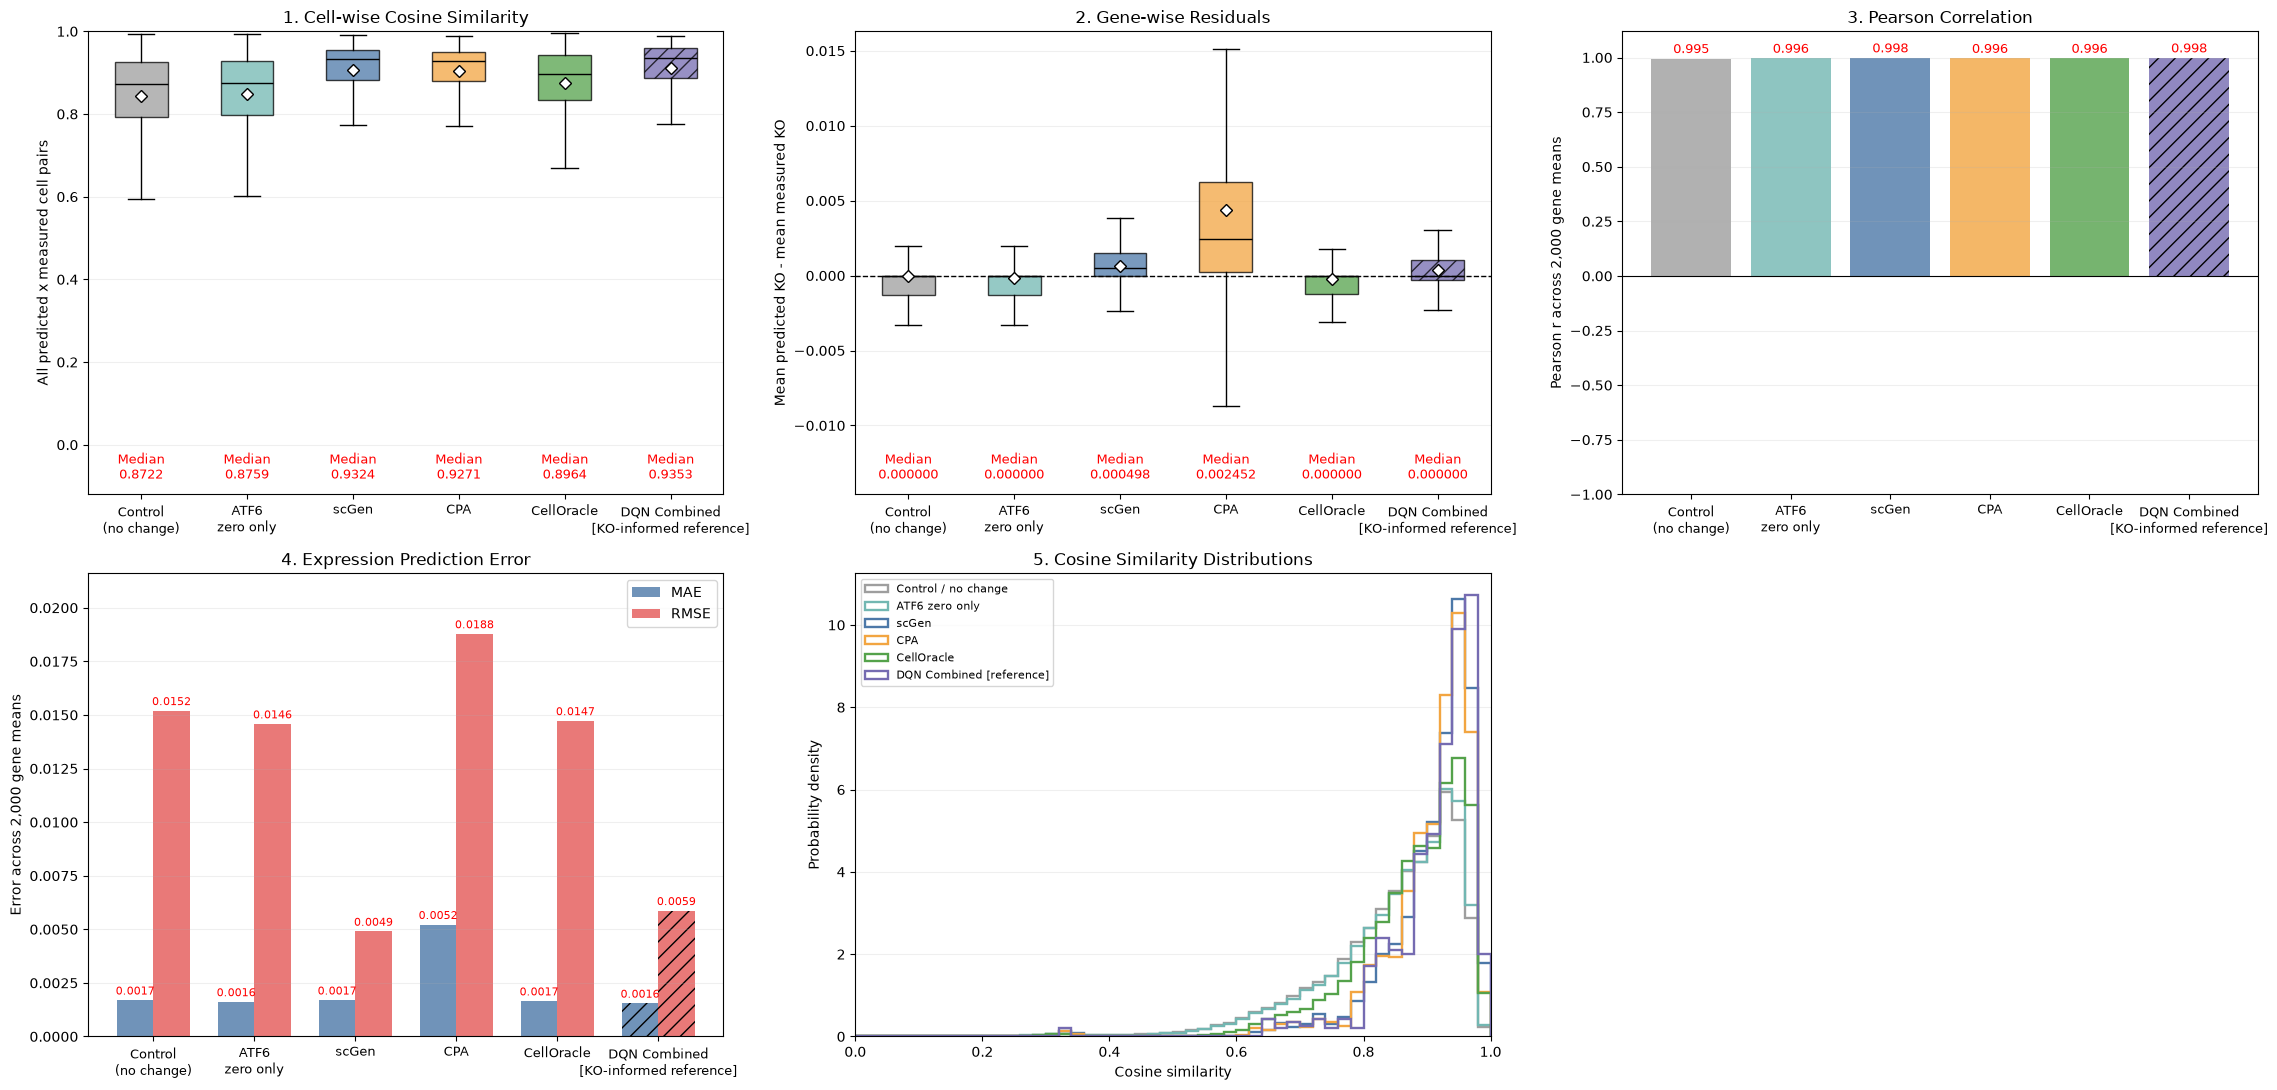

Actual external tools evaluated: 3
Two sanity baselines are not counted as tools. DQN is reference-only.
Saved five-metric figure, Pearson/MAE/RMSE summary, residuals, cosine histogram and provenance: /home/Data_Drive_8TB/kykim/0. Jupyter/RL/total_benchmark_results/supervised_atf6_v1/evaluation_atf6_decrease_only_consistent_reference_v4_metrics_1_6_7_8_12


In [4]:
summary, candidate_status, figure = run_five_metric_benchmark(
    benchmark_data, OUTPUT_DIR, EXTERNAL_RESULTS, DQN_PROVENANCE, seed=SEED,
)
display(summary)
display(candidate_status)
plt.show()
print('Actual external tools evaluated:', candidate_status['status'].eq('evaluated_supplied_prediction').sum())
print('Two sanity baselines are not counted as tools. DQN is reference-only.')
print('Saved five-metric figure, Pearson/MAE/RMSE summary, residuals, cosine histogram and provenance:', OUTPUT_DIR)


In [5]:
from total_benchmark import load_external_prediction
assert len(benchmark_data.genes) == 2000
assert candidate_status['status'].eq('evaluated_supplied_prediction').sum() == 3
assert len(benchmark_data.measured) == 241
for entry in EXTERNAL_RESULTS:
    values, manifest = load_external_prediction(
        entry['method'], Path(entry['prediction_path']), Path(entry['manifest_path']), benchmark_data,
    )
    assert values.shape == (343, 2000)
    assert not set(manifest['training_barcodes']).intersection(benchmark_data.real_barcodes)
    assert not set(manifest['validation_barcodes']).intersection(benchmark_data.real_barcodes)
    row = summary.loc[summary['method'].eq(entry['method'])].iloc[0]
    assert row['n_cosine_pairs'] == 343 * 241
test_x = np.ones((2, 2000), dtype=np.float32)
test_metrics = evaluate_expression(test_x, test_x)
assert test_metrics['n_cosine_pairs'] == 4
np.testing.assert_allclose(test_metrics['residual'], 0)
np.testing.assert_allclose(test_metrics['cosine'], 1, atol=1e-6)
assert (OUTPUT_DIR / 'validation2_tool_comparison.png').is_file()
assert (OUTPUT_DIR / 'five_metric_comparison.png').is_file()
assert len(figure.axes) == 6
assert figure._suptitle is None and not figure.axes[5].texts
for panel, axis in enumerate(figure.axes[:5], start=1):
    assert axis.get_title().startswith(f'{panel}. ')
for axis in figure.axes[:4]:
    assert axis.texts and all(text.get_color() == 'red' for text in axis.texts)
assert summary['gene_Pearson_r'].between(-1, 1).all()
histogram = pd.read_csv(OUTPUT_DIR / 'cosine_histogram_50bins.csv')
for method in summary['method']:
    method_hist = histogram.loc[histogram['method'].eq(method)]
    assert len(method_hist) == 50
    expected_pairs = int(summary.loc[summary['method'].eq(method), 'n_cosine_pairs'].iloc[0])
    assert method_hist['count'].sum() == expected_pairs
    np.testing.assert_allclose((method_hist['probability_density'] * (method_hist['bin_right'] - method_hist['bin_left'])).sum(), 1)
dqn_row = summary.loc[summary['role'].eq('reference_only_KO_informed')].iloc[0]
assert dqn_row['n_predicted_cells'] == sum(np.bincount(benchmark_data.density_band))
provenance = json.loads((OUTPUT_DIR / 'benchmark_provenance.json').read_text())
assert provenance['metric_numbers'] == [1, 6, 7, 8, 12]
assert provenance['latest_DQN']['export_sha256'] == DQN_PROVENANCE['export_sha256']
print('Three real tool predictions, common 2000 genes, disjoint holdout IDs and metric/output checks passed.')


Three real tool predictions, common 2000 genes, disjoint holdout IDs and metric/output checks passed.
